In [1]:
print("Hello")


Hello


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'Unemployment_Rate_upto_11_2020.csv'

In [4]:
import os

print(os.getcwd())

C:\Users\kanad\OneDrive\Desktop\Unemployment_Analysis


In [5]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'images', 'README.md.txt', 'requirements.txt.txt', 'Unemployment_Analysis.ipynb', 'unemployment_rate_upto_11_2020.csv']


In [6]:
df = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")

In [7]:
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 42.1 KB


In [9]:
df.isnull().sum()

Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

In [10]:
df.columns = df.columns.str.strip()

In [11]:
df['Date'] = pd.to_datetime(df['Date'])

C:\Users\kanad\AppData\Local\Temp\ipykernel_19036\2394721818.py:1: UserWarning: Parsing dates in  %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Date'] = pd.to_datetime(df['Date'])


In [12]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

In [13]:
df['Date'] = pd.to_datetime(df['Date'])

In [14]:
df.describe()

,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094


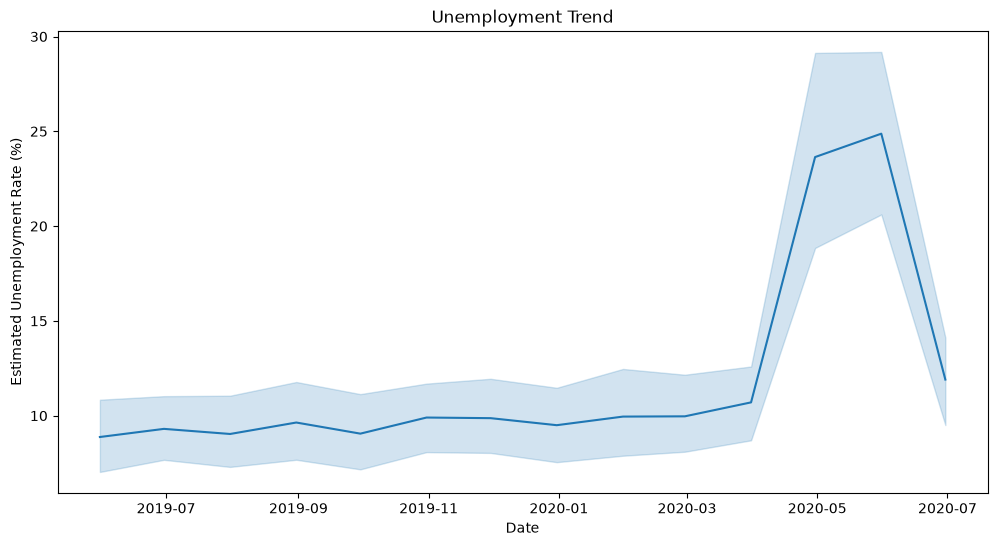

In [15]:
plt.figure(figsize=(12,6))

sns.lineplot(data=df,
             x='Date',
             y='Estimated Unemployment Rate (%)')

plt.title("Unemployment Trend")

plt.show()

<Axes: xlabel='Region'>

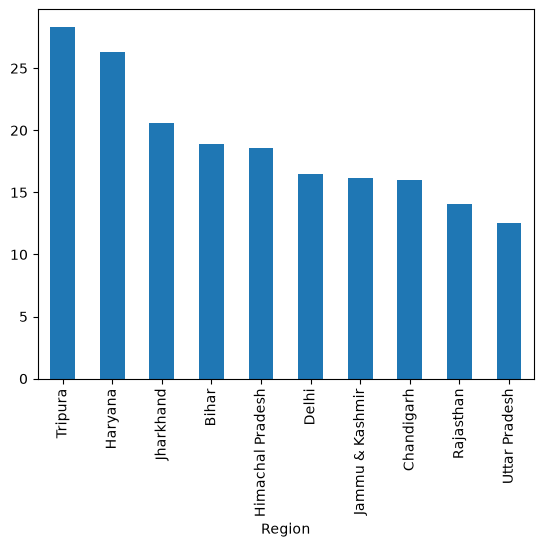

In [16]:
top_states = df.groupby('Region')['Estimated Unemployment Rate (%)'].mean()

top_states = top_states.sort_values(ascending=False).head(10)

top_states.plot(kind='bar')

In [17]:
plt.savefig("images/unemployment_trend.png")

<Figure size 640x480 with 0 Axes>

In [18]:
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


In [19]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

In [20]:
df['Month'] = df['Date'].dt.to_period('M')

In [21]:
monthly_data = df.groupby('Month')['Estimated Unemployment Rate (%)'].mean().reset_index()

In [22]:
monthly_data.head()

,Month,Estimated Unemployment Rate (%)
0,2019-05,8.874259
1,2019-06,9.303333
2,2019-07,9.033889
3,2019-08,9.637925
4,2019-09,9.051731


In [23]:
monthly_data['Month'] = monthly_data['Month'].dt.to_timestamp()

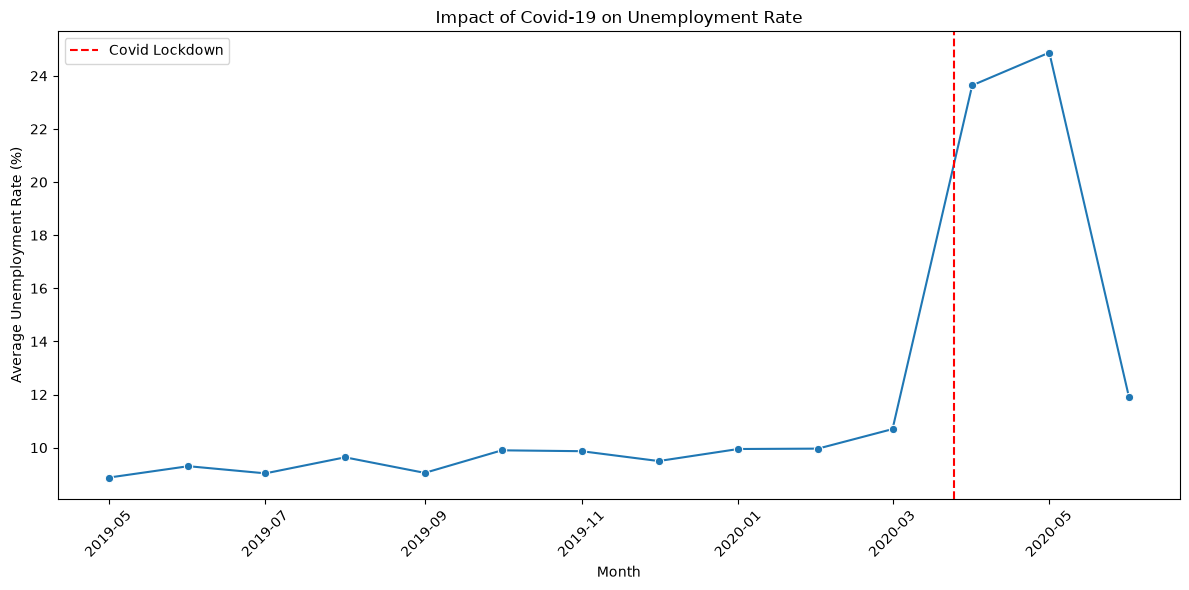

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))

sns.lineplot(
    data=monthly_data,
    x='Month',
    y='Estimated Unemployment Rate (%)',
    marker='o'
)

# Vertical line showing lockdown period
plt.axvline(pd.Timestamp('2020-03-25'),
            color='red',
            linestyle='--',
            label='Covid Lockdown')

plt.title("Impact of Covid-19 on Unemployment Rate")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [25]:
plt.savefig("images/covid_impact.png")

<Figure size 640x480 with 0 Axes>

Text(0, 0.5, 'Average Unemployment Rate (%)')

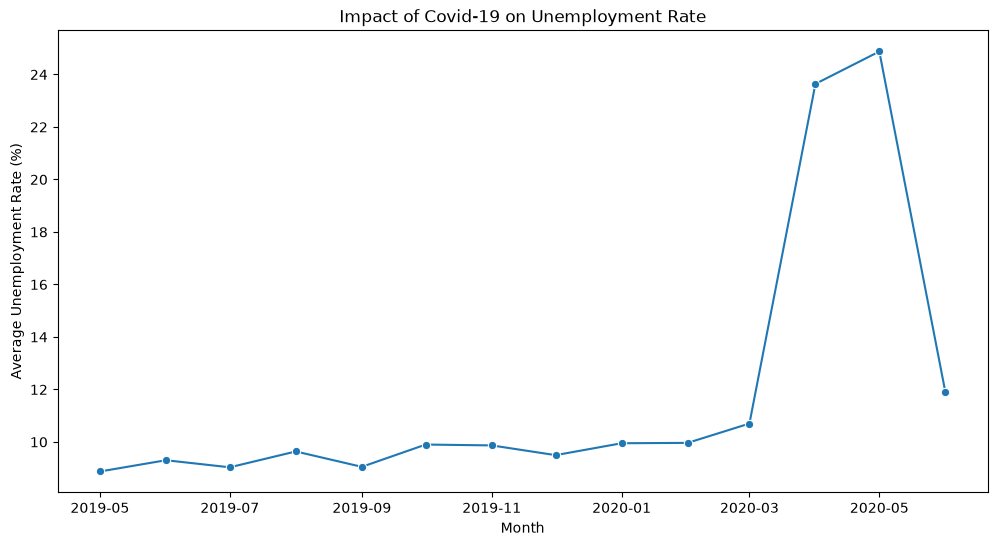

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))

sns.lineplot(
    data=monthly_data,
    x='Month',
    y='Estimated Unemployment Rate (%)',
    marker='o'
)

plt.title("Impact of Covid-19 on Unemployment Rate")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")

In [27]:
plt.savefig("images/covid_impact.png", dpi=300, bbox_inches="tight")

plt.show()

<Figure size 640x480 with 0 Axes>

In [28]:
plt.savefig("images/unemployment_trend.png", dpi=300)

<Figure size 640x480 with 0 Axes>

In [29]:
plt.show()

In [30]:
import os

print(os.getcwd())

C:\Users\kanad\OneDrive\Desktop\Unemployment_Analysis


In [31]:
plt.savefig("images/covid_impact.png", dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

In [32]:
import os

print(os.listdir("images"))

['.ipynb_checkpoints', 'covid_impact.png', 'unemployment_trend.png']


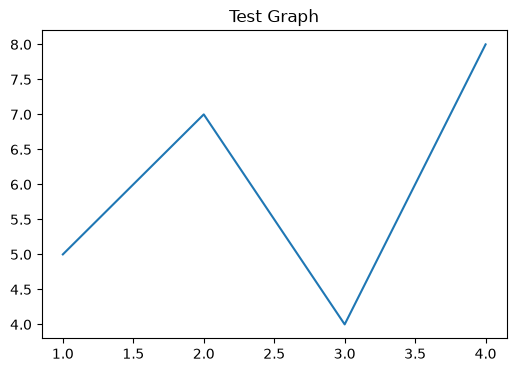

Saved Successfully!
C:\Users\kanad\OneDrive\Desktop\Unemployment_Analysis


In [33]:
import os
import matplotlib.pyplot as plt

# Create images folder if it doesn't exist
os.makedirs("images", exist_ok=True)

# Create a simple graph
plt.figure(figsize=(6,4))
plt.plot([1,2,3,4],[5,7,4,8])

plt.title("Test Graph")

# Save graph
plt.savefig("images/test_graph.png", dpi=300)

plt.show()

print("Saved Successfully!")
print(os.getcwd())

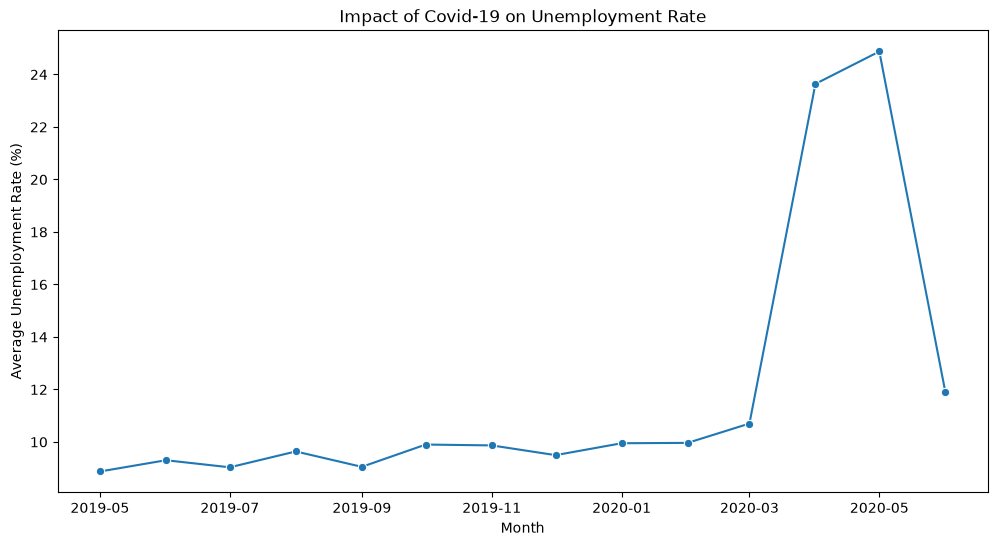

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))

sns.lineplot(
    data=monthly_data,
    x='Month',
    y='Estimated Unemployment Rate (%)',
    marker='o'
)

plt.title("Impact of Covid-19 on Unemployment Rate")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")

# Save the graph
plt.savefig("images/covid_impact.png", dpi=300, bbox_inches="tight")

# Display the graph
plt.show()

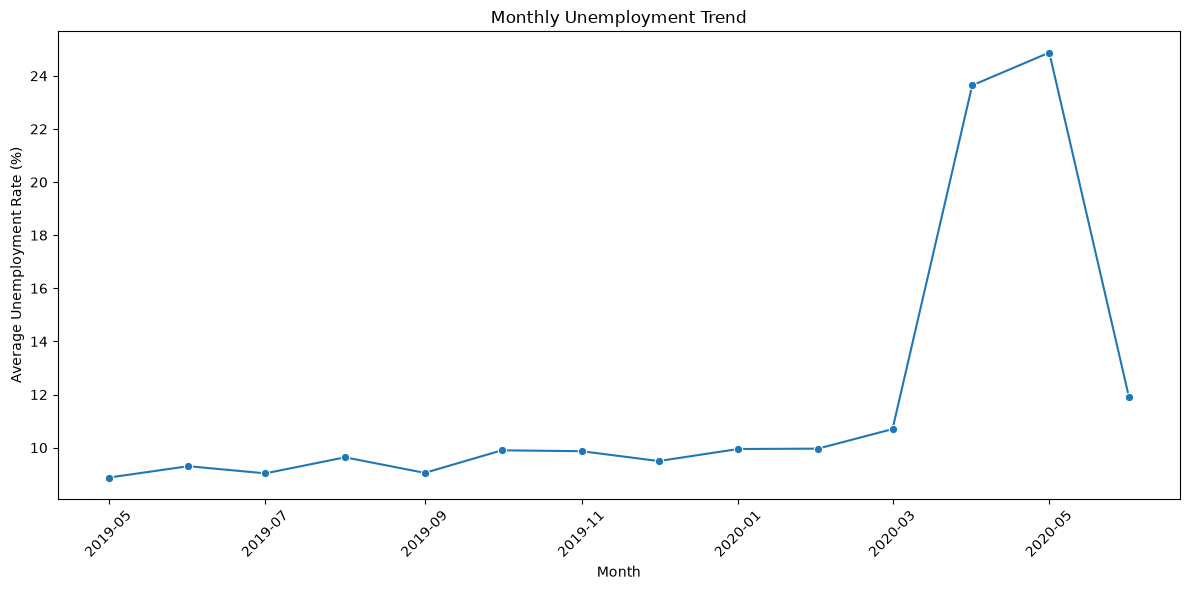

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create images folder if it doesn't exist
os.makedirs("images", exist_ok=True)

plt.figure(figsize=(12,6))

sns.lineplot(
    data=monthly_data,
    x='Month',
    y='Estimated Unemployment Rate (%)',
    marker='o'
)

plt.title("Monthly Unemployment Trend")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()

# Save graph
plt.savefig("images/unemployment_trend.png", dpi=300, bbox_inches="tight")

# Display graph
plt.show()

# Close figure
plt.close()

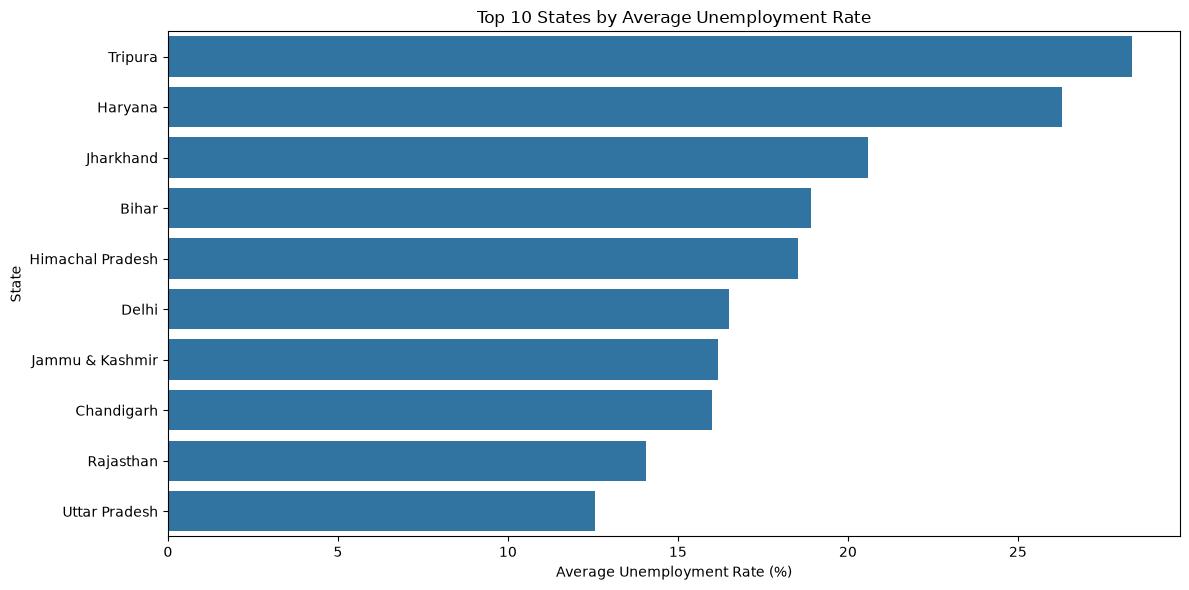

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create images folder if it doesn't exist
os.makedirs("images", exist_ok=True)

# Average unemployment rate by state
state_data = (
    df.groupby('Region')['Estimated Unemployment Rate (%)']
      .mean()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=state_data.values,
    y=state_data.index
)

plt.title("Top 10 States by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("State")

plt.tight_layout()

# Save graph
plt.savefig("images/state_wise.png", dpi=300, bbox_inches="tight")

# Display graph
plt.show()

# Close figure
plt.close()

In [37]:
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area,Month
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,2019-05
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,2019-06
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,2019-07
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural,2019-08
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural,2019-09


In [38]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    str           
 1   Date                                     740 non-null    datetime64[us]
 2   Frequency                                740 non-null    str           
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    str           
 7   Month                                    740 non-null    period[M]     
dtypes: datetime64[us](1), float64(3), period[M](1), str(3)
memory usage: 48.1 KB


Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
Month                                      28
dtype: int64

In [39]:
df['Region'].nunique()

28